In [1]:
from pathlib import Path

import hdbscan
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
print('Libraries loaded')

Libraries loaded


### Load CSV & Prepare features by imputing missing values with medians and standardising

In [2]:
FEATURES = [
    "ltv", "loop_depth", "distance_to_liq",
    "ltv_vol_7d", "ltv_vol_14d",
    "rebal_freq_7d", "rebal_freq_30d", "days_since_rebalance",
    "ltv_lag_7", "carry_spread", "carry_spread_levered",
]
panel = pd.read_csv("panel_cluster_ready.csv", parse_dates=["date"])
medians = panel[FEATURES].median()
scaler = StandardScaler().fit(panel[FEATURES].fillna(medians))
X = scaler.transform(panel[FEATURES].fillna(medians))

### Assign each whale equal weight in HDBSCAN so high-day whales (W-11, W-10) do not dominate.

In [3]:
fit_pool = panel[panel.groupby("whale_id")["whale_id"].transform("count") >= 8]
rng = np.random.default_rng(42)
n_per = fit_pool.groupby("whale_id").size().min()
idx = [i for _, g in fit_pool.groupby("whale_id") for i in rng.choice(g.index, n_per, replace=False)]
X_bal = scaler.transform(panel.loc[idx, FEATURES].fillna(medians))
print(f"rows: {len(panel)} | fit: {len(idx)} ({n_per}/whale)")

rows: 1750 | fit: 128 (8/whale)


### Parameter sweep on balanced fit

In [4]:
for mcs in [8, 10, 12]:
    for ms in [3, 5]:
        lb = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=ms).fit_predict(X_bal)
        ncl = sum(1 for c in set(lb) if c >= 0)
        print(f"min_cluster_size={mcs}, min_samples={ms} → {ncl} clusters")
        print(pd.Series(lb).value_counts().sort_index())
        print()

min_cluster_size=8, min_samples=3 → 3 clusters
-1    64
 0    42
 1    13
 2     9
Name: count, dtype: int64

min_cluster_size=8, min_samples=5 → 3 clusters
-1    77
 0    11
 1     9
 2    31
Name: count, dtype: int64

min_cluster_size=10, min_samples=3 → 2 clusters
-1    64
 0    22
 1    42
Name: count, dtype: int64

min_cluster_size=10, min_samples=5 → 2 clusters
-1    71
 0    11
 1    46
Name: count, dtype: int64

min_cluster_size=12, min_samples=3 → 2 clusters
-1    64
 0    22
 1    42
Name: count, dtype: int64

min_cluster_size=12, min_samples=5 → 0 clusters
-1    128
Name: count, dtype: int64



we'll use `min_cluster_size=8`, `min_samples=3` for three dense groups on the balanced fit, then name clusters from their feature profiles (not fixed cluster IDs).

### Assign all whale-days to nearest cluster centroid

In [5]:
labels_bal = hdbscan.HDBSCAN(min_cluster_size=8, min_samples=3).fit_predict(X_bal)
clusters = sorted(c for c in set(labels_bal) if c >= 0)
if not clusters:
    raise ValueError("HDBSCAN found no clusters — lower min_cluster_size or widen fit_pool.")
centroids = np.array([X_bal[labels_bal == c].mean(axis=0) for c in clusters])
dists = cdist(X, centroids)
panel["cluster_v2"] = [clusters[i] for i in np.argmin(dists, axis=1)]
panel.loc[dists.min(axis=1) > np.percentile(dists.min(axis=1), 95), "cluster_v2"] = -1
print(panel["cluster_v2"].value_counts().sort_index())

cluster_v2
-1     88
 0    593
 1    402
 2    667
Name: count, dtype: int64


### Unnamed Profile Table

In [6]:
panel.groupby("cluster_v2")[FEATURES].mean().round(3)

,ltv,loop_depth,distance_to_liq,ltv_vol_7d,ltv_vol_14d,rebal_freq_7d,rebal_freq_30d,days_since_rebalance,ltv_lag_7,carry_spread,carry_spread_levered
cluster_v2,,,,,,,,,,,
-1,0.280,2.341,0.662,0.214,0.314,2.159,6.466,3.705,0.594,12.883,69.335
0,0.900,12.919,0.042,0.001,0.002,0.358,1.523,49.479,0.898,7.477,70.170
1,0.670,7.435,0.237,0.020,0.031,3.403,9.440,1.144,0.663,7.335,37.957
2,0.338,2.273,0.547,0.001,0.010,0.385,3.787,35.345,0.329,6.228,13.808


these are raw numbers used to pick names in the next cell

### Archetype Names

In [7]:
prof = panel[panel["cluster_v2"] >= 0].groupby("cluster_v2")[["ltv", "loop_depth", "days_since_rebalance"]].mean()
remaining = list(prof.index)
name_map = {}
hi = prof["ltv"].idxmax()
name_map[hi] = "high-LTV hold"
remaining.remove(hi)
mod = prof.loc[remaining, "days_since_rebalance"].idxmin()
name_map[mod] = "moderate leverage"
remaining.remove(mod)
name_map[remaining[0]] = "stale / light loop"
CLUSTER_LABELS = {-1: "idle / outlier", **name_map}
panel["cluster_name"] = panel["cluster_v2"].map(CLUSTER_LABELS)
panel.groupby(["cluster_v2", "cluster_name"])[FEATURES].mean().round(3)

,,ltv,loop_depth,distance_to_liq,ltv_vol_7d,ltv_vol_14d,rebal_freq_7d,rebal_freq_30d,days_since_rebalance,ltv_lag_7,carry_spread,carry_spread_levered
cluster_v2,cluster_name,,,,,,,,,,,
-1,idle / outlier,0.280,2.341,0.662,0.214,0.314,2.159,6.466,3.705,0.594,12.883,69.335
0,high-LTV hold,0.900,12.919,0.042,0.001,0.002,0.358,1.523,49.479,0.898,7.477,70.170
1,moderate leverage,0.670,7.435,0.237,0.020,0.031,3.403,9.440,1.144,0.663,7.335,37.957
2,stale / light loop,0.338,2.273,0.547,0.001,0.010,0.385,3.787,35.345,0.329,6.228,13.808


The four archetypes separate cleanly on two dimensions: **leverage intensity** (LTV + loop depth) and **maintenance style** (rebalancing frequency).

- **high-LTV hold** runs at the protocol limit (LTV 0.90, loop 13×) with only 4% buffer to liquidation, but rarely touches the position (50 days since last rebalance). These are set-and-forget max-yield chasers.
- **moderate leverage** uses mid-range leverage (LTV 0.67, loop 7×) but rebalances constantly (every 1.1 days on average). Active risk managers trading off yield for tighter control.
- **stale / light loop** sits at low leverage (LTV 0.34, loop 2×) with wide buffers but hasn't rebalanced in 35 days. These are either winding down or parking capital with minimal attention.
- **idle / outlier** is near-unwound (LTV 0.28) or geometrically distant from all centroids — transitional days between strategies.

The key insight: **stale rebalancing does not mean high risk**. Stale / light loop is stale *because* the position is conservative — there's nothing to rebalance. High-LTV hold is stale *despite* running hot, which is the dangerous combination.


### PCA By Archetype

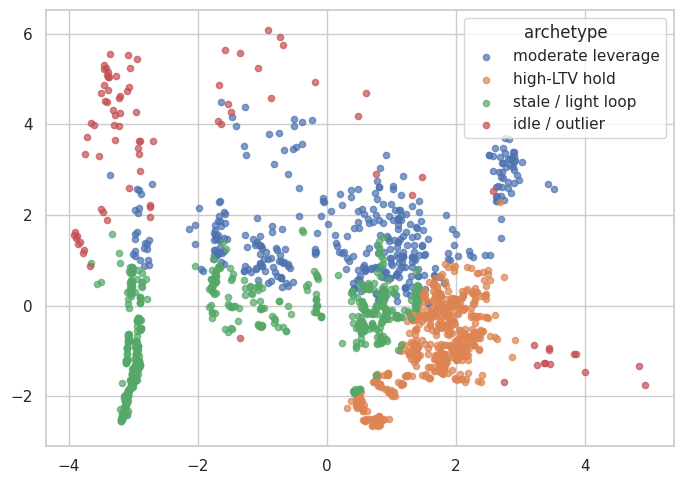

In [8]:
pca = PCA(n_components=2, random_state=42).fit_transform(X)
panel["x"], panel["y"] = pca[:, 0], pca[:, 1]
order = ["moderate leverage", "high-LTV hold", "stale / light loop", "idle / outlier"]
plt.figure(figsize=(7, 5))
for name in order:
    s = panel[panel["cluster_name"] == name]
    if len(s):
        plt.scatter(s["x"], s["y"], label=name, alpha=0.7, s=20)
plt.legend(title="archetype")
plt.tight_layout()
plt.show()

- High-LTV hold — right-hand cloud below the midline: highest LTV (~0.90) and deepest loop (~13). W-2 (92%), W-6 and W-12 (100%), plus most of W-10, W-13, and W-14.
- Stale / light loop — left of centre, below the midline: lower LTV (~0.34), shallow loop, long gaps since rebalance (~35d). Dominated by W-11 (71%), W-4, and W-5.
- Moderate leverage — centre/upper band: mid LTV (~0.67), more active rebalance (~1d stale). Core of W-7 (79%), W-15 (88%, 8d), W-3, W-9, and W-16.
- Idle / outlier — top-left fringe: near-zero LTV unwind days plus centroid-distance outliers; tails of W-13, W-16, W-2, and W-10.

In [9]:
membership = (
    panel.groupby(["whale_id", "cluster_name"]).size()
    .groupby(level=0, group_keys=False)
    .apply(lambda s: (s / s.sum() * 100).round(1))
    .unstack(fill_value=0)
)
print(membership.to_string())

strategist_type = np.where(membership.max(axis=1) >= 80, "pure", "mixed")
print("\nstrategist type (pure = ≥80% one archetype):")
print(pd.Series(strategist_type, index=membership.index, name="strategist_type"))
panel["strategist_type"] = panel["whale_id"].map(
    pd.Series(strategist_type, index=membership.index)
)
panel["moderate_sub"] = np.where(
    panel["cluster_name"] != "moderate leverage",
    pd.NA,
    np.where(panel["ltv"] < 0.6, "moderate_light", "moderate_core"),
)

cluster_name  high-LTV hold  idle / outlier  moderate leverage  stale / light loop
whale_id                                                                          
W-1                    36.4             0.0               35.1                28.6
W-10                   79.8             5.1                0.0                15.0
W-11                    1.6             1.3               26.2                70.9
W-12                  100.0             0.0                0.0                 0.0
W-13                   55.6            17.4                4.2                22.9
W-14                   54.9            11.5               25.7                 8.0
W-15                   12.5             0.0               87.5                 0.0
W-16                    0.0            27.0               51.4                21.6
W-17                    0.0             0.0                0.0               100.0
W-2                    92.0             8.0                0.0                 0.0
W-3 

**Key distinction: archetype (day-level) vs strategist type (whale-level)**

- **Archetypes** are assigned *per day*: high-LTV hold, moderate leverage, stale / light loop, idle / outlier
- **Strategist type** summarises a whale's overall behaviour: if ≥80% of days fall in ONE archetype → `pure`; otherwise → `mixed`

Examples:
- W-12 is **pure** high-LTV hold (100% of its 70 days)
- W-3 is **mixed** (only 56% moderate, spreads across all four archetypes)
- W-7 is **mixed** (79% moderate — just under the 80% threshold)

The `moderate_sub` column further splits moderate leverage days by LTV: `moderate_light` (LTV < 0.6, conservative) vs `moderate_core` (LTV ≥ 0.6, higher-risk active).

### Save to Panel Archetypes CSV

In [10]:
panel.to_csv("panel_archetypes.csv", index=False)
print(f"saved panel_archetypes.csv ({len(panel)} rows)")

saved panel_archetypes.csv (1750 rows)


### Next Steps

- Join stressed_state from whale_features_labeled.csv → done in `04_stressed_by_archetype.ipynb`.
- Use `strategist_type` (pure/mixed) for whale-level RQ1 narrative; use `moderate_sub` for within-moderate splits.
- Cross stressed days with `days_since_rebalance` per archetype to test the RQ3 mechanism.
- Paper: link RQ1/RQ2 archetypes + membership % to RQ3 (stress = instant LTV; rebalancing = lagged leverage history).